
--- Running qfl-avg on MNIST ---
Round 01: Acc=0.5139
Round 05: Acc=0.6528
Round 10: Acc=0.7639
Round 15: Acc=0.8194
Round 20: Acc=0.8611
Total Time: 103.69s

--- Running qfl-avg on ADNI ---
Round 01: Acc=0.5312
Round 05: Acc=0.5500
Round 10: Acc=0.5875
Round 15: Acc=0.6250
Round 20: Acc=0.6687
Total Time: 104.39s

--- Running qfl-fisher on MNIST ---
Round 01: Acc=0.5417
Round 05: Acc=0.8056
Round 10: Acc=0.8889
Round 15: Acc=0.8889
Round 20: Acc=0.9306
Total Time: 103.99s

--- Running qfl-fisher on ADNI ---
Round 01: Acc=0.5312
Round 05: Acc=0.6000
Round 10: Acc=0.7188
Round 15: Acc=0.7937
Round 20: Acc=0.8187
Total Time: 103.70s

--- Running qfl-qgt on MNIST ---
Round 01: Acc=0.5278
Round 05: Acc=0.7778
Round 10: Acc=0.8889
Round 15: Acc=0.9444
Round 20: Acc=0.9861
Total Time: 103.74s

--- Running qfl-qgt on ADNI ---
Round 01: Acc=0.5250
Round 05: Acc=0.5750
Round 10: Acc=0.7250
Round 15: Acc=0.8063
Round 20: Acc=0.8187
Total Time: 104.46s


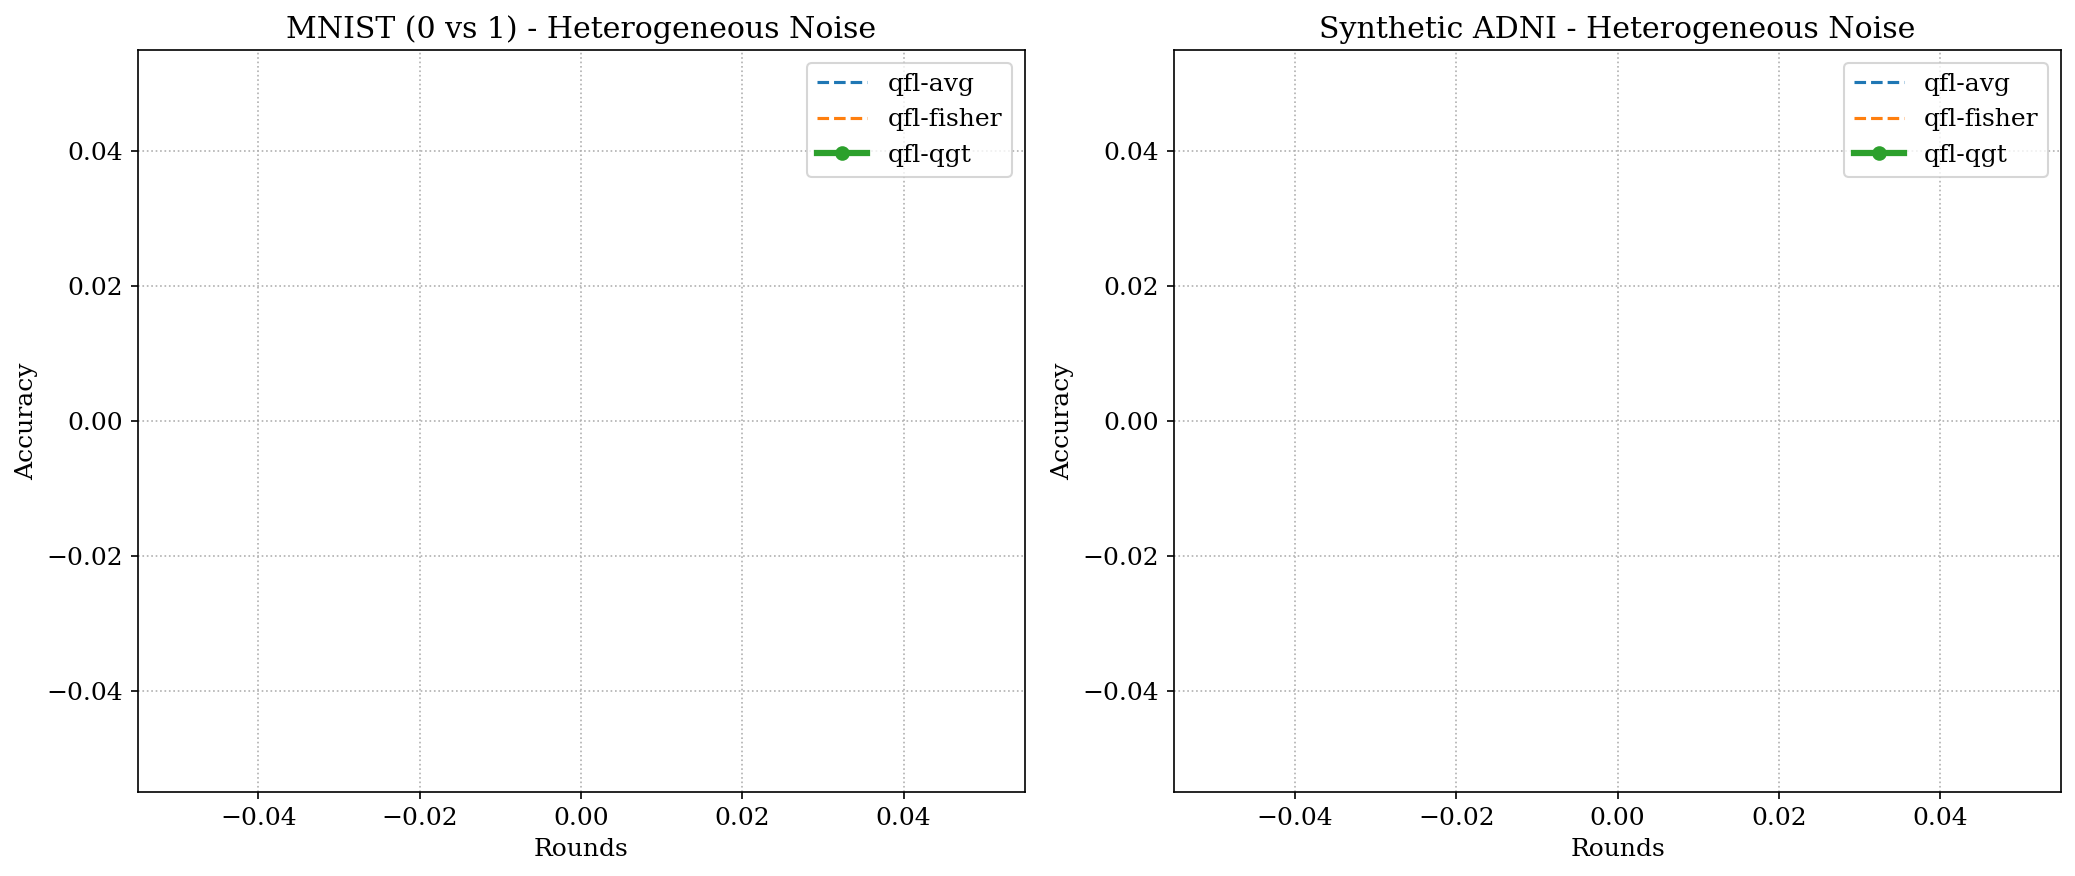

In [4]:
"""
Extended Quantum Natural Gradient in QFL (QFL-QGT)
Fixes: 
1. Changed to Binary Cross Entropy (BCE) loss for stable classification.
2. Stabilized QGT inversion with stronger damping.
3. Corrected EQNG update rule for better utilization of imaginary parts.
4. Adjusted data scaling to [0, pi] to avoid phase wrapping.
"""

import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from joblib import Parallel, delayed
import time

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'serif'
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.size"] = 12

# ==========================================
# 1. Fast VQC with Statevector (Full QGT)
# ==========================================
class FastVQC:
    def __init__(self, n_qubits, n_layers):
        self.n_qubits = n_qubits
        self.n_layers = n_layers
        self.backend = AerSimulator(method='statevector') 
        
        self.qc = QuantumCircuit(n_qubits)
        self.n_data_params = n_qubits * n_layers
        self.n_train_params = 3 * n_qubits * n_layers
        
        self.x_p = ParameterVector('x', self.n_data_params)
        self.th_p = ParameterVector('th', self.n_train_params)
        
        x_idx = 0
        th_idx = 0
        
        for l in range(n_layers):
            # Hardware-efficient data encoding
            for i in range(n_qubits):
                self.qc.ry(self.x_p[x_idx], i)
                x_idx += 1
            
            # Universal 1-qubit trainable layers
            for i in range(n_qubits):
                self.qc.rz(self.th_p[th_idx], i); th_idx += 1
                self.qc.ry(self.th_p[th_idx], i); th_idx += 1
                self.qc.rz(self.th_p[th_idx], i); th_idx += 1
                
            # Linear entanglement (Ring can be too dense for few qubits)
            for i in range(n_qubits - 1):
                self.qc.cx(i, i + 1)
        
        self.qc.save_statevector() 
        self.compiled_circuit = transpile(self.qc, self.backend)

    def _prepare_data_params(self, x):
        mapped_x = []
        for l in range(self.n_layers):
            for i in range(self.n_qubits):
                mapped_x.append(float(x[i])) 
        return mapped_x

    def run_batch_states(self, x_batch, theta_val):
        bound_circuits = []
        for x in x_batch:
            x_mapped = self._prepare_data_params(x)
            bind_dict = {}
            for p, v in zip(self.x_p, x_mapped): bind_dict[p] = v
            for p, v in zip(self.th_p, theta_val): bind_dict[p] = float(v)
            bound_qc = self.compiled_circuit.assign_parameters(bind_dict)
            bound_circuits.append(bound_qc)
            
        job = self.backend.run(bound_circuits)
        result = job.result()
        
        states = [result.get_statevector(i) for i in range(len(bound_circuits))]
        return np.array(states)

    def compute_gradient_and_full_qgt(self, x_batch, y_batch, theta, shots_budget):
        n_samples = len(x_batch)
        n_params = len(theta)
        delta = 1e-3 
        
        states_curr = self.run_batch_states(x_batch, theta)
        # Probability of state |00...0> as class 0
        probs_curr = np.abs(states_curr[:, 0])**2
        # Avoid exactly 0 or 1 for BCE stability
        probs_curr = np.clip(probs_curr, 1e-7, 1 - 1e-7) 
        
        d_states = np.zeros((n_samples, n_params, len(states_curr[0])), dtype=np.complex128)
        grads = np.zeros((n_samples, n_params))
        
        for i in range(n_params):
            tp = theta.copy(); tp[i] += delta
            tm = theta.copy(); tm[i] -= delta
            
            st_p = self.run_batch_states(x_batch, tp)
            st_m = self.run_batch_states(x_batch, tm)
            
            d_states[:, i, :] = (st_p - st_m) / (2 * delta)
            
            pr_p = np.abs(st_p[:, 0])**2
            pr_m = np.abs(st_m[:, 0])**2
            grad_p = (pr_p - pr_m) / (2 * delta)
            
            # BCE Loss Gradient: L = -y log(p) - (1-y) log(1-p)
            # dL/dth = (p - y) / (p * (1 - p)) * dp/dth
            targets = 1.0 - y_batch # 1 if y=0, 0 if y=1
            grad_l = (probs_curr - targets) / (probs_curr * (1.0 - probs_curr)) * grad_p
            grads[:, i] = grad_l
            
        mean_grad = np.mean(grads, axis=0)
        
        # Construct Full QGT
        Q_batch = np.zeros((n_samples, n_params, n_params), dtype=np.complex128)
        for s in range(n_samples):
            psi = states_curr[s]
            dpsi = d_states[s] 
            
            term1 = np.conj(dpsi) @ dpsi.T
            di_psi = np.conj(dpsi) @ psi
            psi_dj = np.conj(di_psi)
            term2 = np.outer(di_psi, psi_dj)
            
            Q_batch[s] = term1 - term2
            
        mean_qgt = np.mean(Q_batch, axis=0)
        
        if shots_budget < float('inf'):
            noise_scale = 1.0 / np.sqrt(shots_budget)
            mean_grad += np.random.normal(0, noise_scale, size=mean_grad.shape)
            
            q_noise = np.random.normal(0, noise_scale * 0.01, size=mean_qgt.shape) + 1j * np.random.normal(0, noise_scale * 0.01, size=mean_qgt.shape)
            q_noise = (q_noise + np.conj(q_noise).T) / 2 
            mean_qgt += q_noise
            
        return mean_grad, mean_qgt

    def predict_batch(self, x_batch, theta):
        states = self.run_batch_states(x_batch, theta)
        return np.abs(states[:, 0])**2

# ==========================================
# 2. Client Task
# ==========================================
def client_update_task(client_data, global_theta, mode, shots_budget, vqc_config):
    X, y = client_data
    n_qubits, n_layers = vqc_config
    
    vqc = FastVQC(n_qubits, n_layers)
    theta = global_theta.copy()
    
    lr = 0.05
    epochs = 10  # Increased local steps for better convergence
    batch_size = 16
    
    avg_qgt = np.zeros((len(theta), len(theta)), dtype=np.complex128)
    m = np.zeros_like(theta)
    beta = 0.9
    
    for ep in range(epochs):
        idxs = np.random.choice(len(X), batch_size, replace=False)
        X_b, y_b = X[idxs], y[idxs]
        
        grad, full_qgt = vqc.compute_gradient_and_full_qgt(X_b, y_b, theta, shots_budget)
        avg_qgt += full_qgt
        
        if mode == 'qfl-qgt':
            # --- Extended Quantum Natural Gradient (EQNG) Stabilization ---
            epsilon = 0.05 # Stronger damping to prevent singular matrix issues
            g_metric = np.real(full_qgt) # Fubini-Study
            omega = np.imag(full_qgt)    # Berry Curvature
            
            qgt_reg = g_metric + epsilon * np.eye(len(theta))
            try:
                qgt_inv = np.linalg.inv(qgt_reg)
            except:
                qgt_inv = np.linalg.pinv(qgt_reg)
                
            nat_grad = qgt_inv @ grad
            
            # Incorporate Berry curvature as a "magnetic field" momentum rotation
            alpha = 0.05
            berry_force = omega @ nat_grad
            update = nat_grad + alpha * berry_force
            
            # Gradient Clipping
            norm = np.linalg.norm(update)
            if norm > 1.0: update = update / norm
            
            theta -= lr * update
            
        elif mode == 'qfl-fisher':
            # QFedFisher local update uses diagonal Fisher
            fisher_diag = np.real(np.diag(full_qgt)) + 0.01
            update = grad / fisher_diag
            norm = np.linalg.norm(update)
            if norm > 1.0: update = update / norm
            theta -= lr * update
            
        else: 
            # SGD (QFedAvg)
            m = beta * m + (1 - beta) * grad
            theta -= lr * m
            
    sigma_k = 1.0 / np.sqrt(shots_budget) if shots_budget < float('inf') else 1e-3
    return theta, avg_qgt / epochs, sigma_k

# ==========================================
# 3. Server
# ==========================================
class Server:
    def __init__(self, mode, n_params):
        self.mode = mode
        # Initialize near zero
        self.global_theta = np.random.normal(0, 0.1, n_params)
        self.history_acc = []

    def aggregate(self, client_results):
        if self.mode == 'qfl-avg':
            self.global_theta = np.mean([r[0] for r in client_results], axis=0)
            
        elif self.mode == 'qfl-fisher':
            num = np.zeros_like(self.global_theta)
            den = np.zeros_like(self.global_theta)
            
            for theta, full_qgt, _ in client_results:
                fisher_diag = np.real(np.diag(full_qgt)) + 1e-4
                num += fisher_diag * theta
                den += fisher_diag
                
            self.global_theta = num / den
            
        elif self.mode == 'qfl-qgt':
            gamma = 0.1 
            weights = []
            thetas = []
            
            for theta, full_qgt, sigma in client_results:
                # Use real part (metric) for stability in aggregation
                metric = np.real(full_qgt)
                reg_matrix = metric + gamma * (sigma**2) * np.eye(len(theta))
                
                try:
                    lambda_k = np.linalg.inv(reg_matrix) @ metric
                except:
                    lambda_k = np.linalg.pinv(reg_matrix) @ metric
                
                w = np.linalg.norm(lambda_k, ord='fro')
                weights.append(w)
                thetas.append(theta)
            
            weights = np.array(weights)
            weights = weights / np.sum(weights) # Simple linear normalization
            self.global_theta = np.average(thetas, axis=0, weights=weights)

    def evaluate(self, X_test, y_test, vqc_config):
        vqc = FastVQC(*vqc_config)
        probs = []
        chunk_size = 100
        for i in range(0, len(X_test), chunk_size):
            p_chunk = vqc.predict_batch(X_test[i:i+chunk_size], self.global_theta)
            probs.append(p_chunk)
        probs = np.concatenate(probs)
        
        preds = np.where(probs > 0.5, 0, 1)
        return accuracy_score(y_test, preds)

# ==========================================
# 4. Simulation Runner
# ==========================================
def prepare_data(dataset_name='MNIST', n_clients=5, n_qubits=4):
    if dataset_name == 'MNIST':
        data = datasets.load_digits()
        X, y = data.data, data.target
        mask = (y == 0) | (y == 1)
        X, y = X[mask], y[mask]
    else: 
        X, y = datasets.make_classification(
            n_samples=800, n_features=50, n_classes=2, random_state=42, 
            n_informative=10, class_sep=1.5 # Made slightly easier
        )
    
    # Scale to [0, pi] to prevent phase wrapping ambiguity
    scaler = MinMaxScaler((0, np.pi))
    X = PCA(n_components=n_qubits).fit_transform(X)
    X = scaler.fit_transform(X)
    
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
    data_split = list(zip(np.array_split(X_tr, n_clients), np.array_split(y_tr, n_clients)))
    return data_split, (X_te, y_te)

def run_simulation(dataset_name, mode, n_rounds=20):
    print(f"\n--- Running {mode} on {dataset_name} ---")
    start_time = time.time()
    
    n_clients = 5
    n_qubits = 4
    n_layers = 3 # Increased layers for better capacity
    vqc_config = (n_qubits, n_layers)
    
    client_data_list, test_data = prepare_data(dataset_name, n_clients, n_qubits)
    X_test, y_test = test_data
    
    shot_budgets = [float('inf'), 4096, 512, 128, 16] 
    
    n_params = 3 * n_qubits * n_layers
    server = Server(mode, n_params)
    
    for r in range(n_rounds):
        results = Parallel(n_jobs=n_clients)(
            delayed(client_update_task)(
                client_data_list[i], 
                server.global_theta, 
                mode, 
                shot_budgets[i], 
                vqc_config
            ) 
            for i in range(n_clients)
        )
        
        server.aggregate(results)
        acc = server.evaluate(X_test, y_test, vqc_config)
        
        if (r+1) % 5 == 0 or r == 0:
            print(f"Round {r+1:02d}: Acc={acc:.4f}")
            
    print(f"Total Time: {time.time() - start_time:.2f}s")
    return server.history_acc

if __name__ == "__main__":
    ROUNDS = 20 
    
    modes = ['qfl-avg', 'qfl-fisher', 'qfl-qgt']
    results_mnist = {}
    results_adni = {}
    
    for m in modes:
        results_mnist[m] = run_simulation('MNIST', m, ROUNDS)
        results_adni[m] = run_simulation('ADNI', m, ROUNDS)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    for m, accs in results_mnist.items():
        lw = 3 if m == 'qfl-qgt' else 1.5
        style = 'o-' if m == 'qfl-qgt' else '--'
        axes[0].plot(accs, style, label=m, linewidth=lw)
    axes[0].set_title('MNIST (0 vs 1) - Heterogeneous Noise')
    axes[0].set_ylabel('Accuracy'); axes[0].set_xlabel('Rounds')
    axes[0].legend(); axes[0].grid(True, linestyle=':')
    
    for m, accs in results_adni.items():
        lw = 3 if m == 'qfl-qgt' else 1.5
        style = 'o-' if m == 'qfl-qgt' else '--'
        axes[1].plot(accs, style, label=m, linewidth=lw)
    axes[1].set_title('Synthetic ADNI - Heterogeneous Noise')
    axes[1].set_ylabel('Accuracy'); axes[1].set_xlabel('Rounds')
    axes[1].legend(); axes[1].grid(True, linestyle=':')
    
    plt.tight_layout()
    plt.savefig("qfl-qgt_res_final.pdf")
    plt.show()